# RAG Dataset Exploratory Data Analysis

This notebook reads the cleaned root `dataset.csv`. Run `python scripts/build_dataset.py` from the repository root if the CSV is not present. The `answer` field is a retrieved reference excerpt used for lexical evaluation, not a saved LLM response.

In [1]:
import csv
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

dataset_path = Path('dataset.csv')
if not dataset_path.is_file():
    dataset_path = Path('..') / 'dataset.csv'
with dataset_path.open('r', encoding='utf-8-sig', newline='') as csv_file:
    rows = list(csv.DictReader(csv_file))
if not rows:
    raise ValueError(f'No rows found in {dataset_path}')
chunk_lengths = [len(row['chunk_text']) for row in rows]
scores = [float(row['retrieval_score']) for row in rows]
doc_type_counts = Counter(row['doc_type'] for row in rows)
answer_lengths = [len(row['answer'].split()) for row in rows]
print(f'Loaded {len(rows)} rows from {dataset_path}')

Loaded 16 rows from dataset.csv


## 1. Chunk length distribution

This histogram shows the number of characters per retrieved chunk, helping reveal unusually short or long context segments.

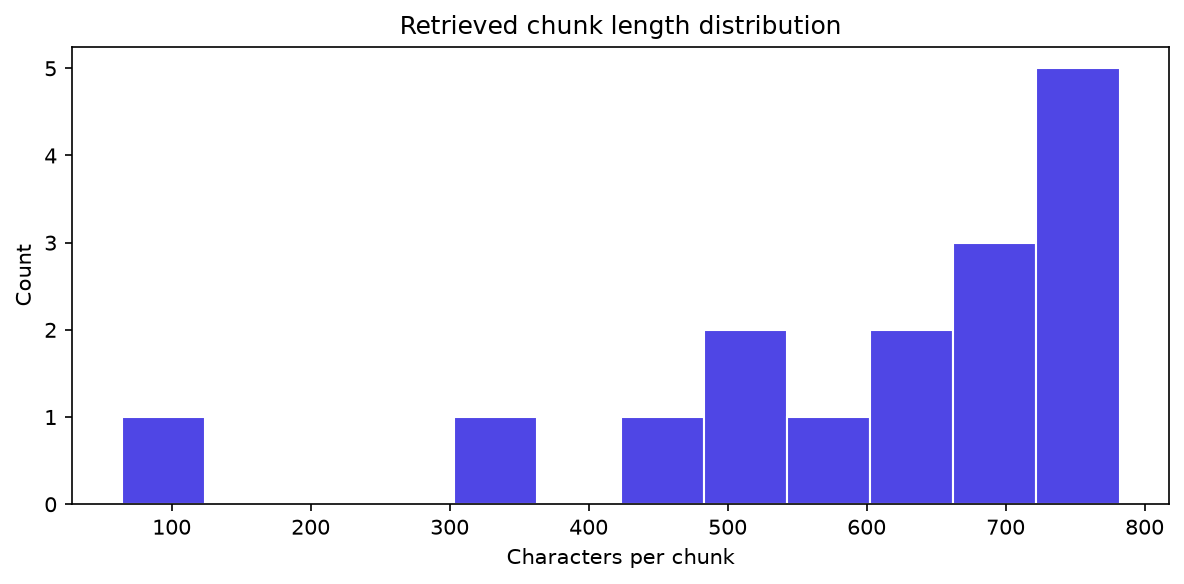

In [2]:
plt.figure(figsize=(8, 4))
plt.hist(chunk_lengths, bins=12, color='#4f46e5', edgecolor='white')
plt.title('Retrieved chunk length distribution')
plt.xlabel('Characters per chunk')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## 2. Retrieval score distribution

This histogram plots Chroma relevance scores for the retrieved query/chunk pairs and shows their spread against the configured relevance threshold.

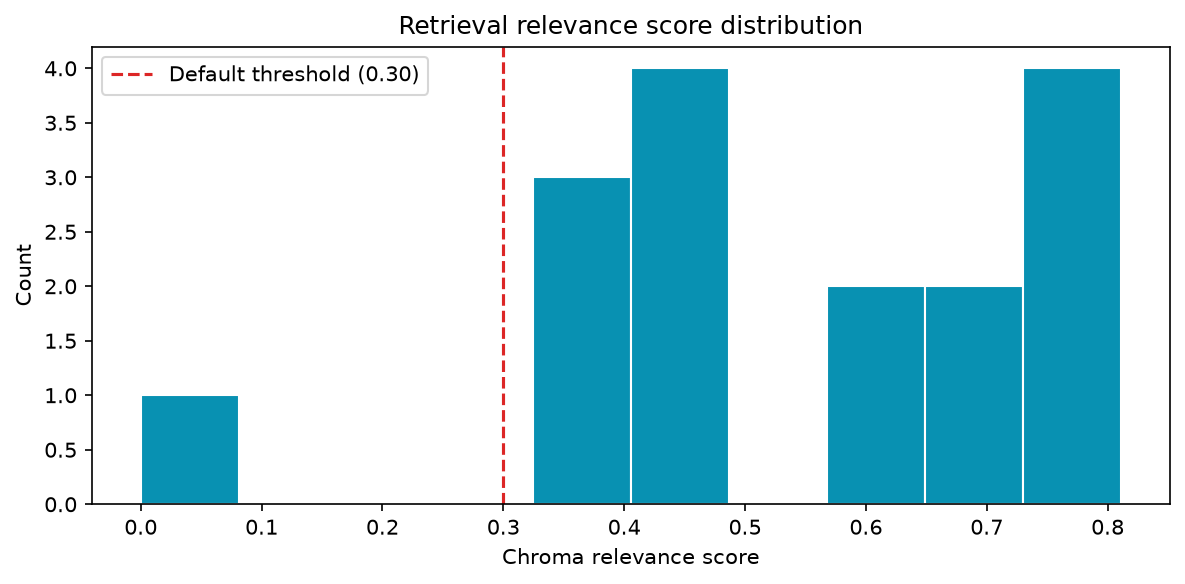

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(scores, bins=10, color='#0891b2', edgecolor='white')
plt.axvline(0.30, color='#dc2626', linestyle='--', label='Default threshold (0.30)')
plt.title('Retrieval relevance score distribution')
plt.xlabel('Chroma relevance score')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

## 3. Document type counts

This bar chart counts retrieved rows by source document type, showing which supported formats contribute data.

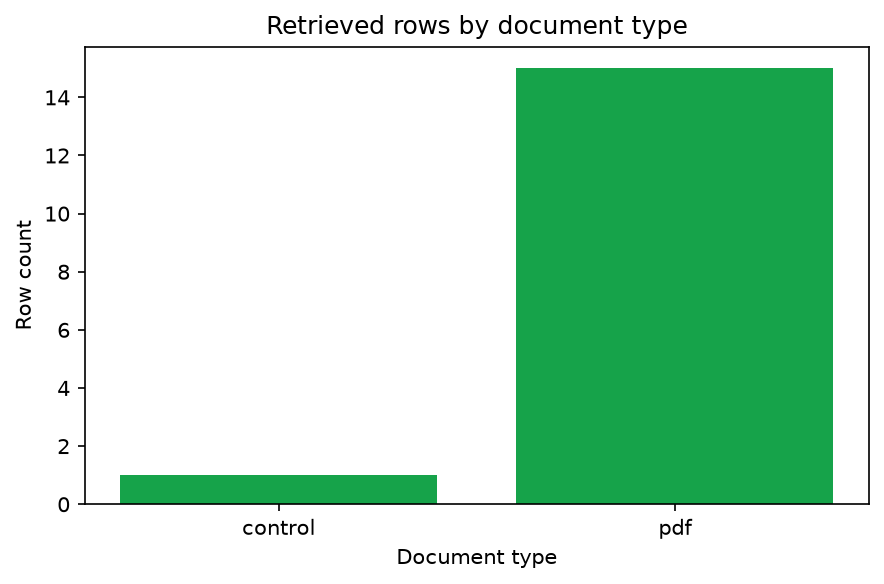

In [4]:
types, counts = zip(*sorted(doc_type_counts.items()))
plt.figure(figsize=(6, 4))
plt.bar(types, counts, color='#16a34a')
plt.title('Retrieved rows by document type')
plt.xlabel('Document type')
plt.ylabel('Row count')
plt.tight_layout()
plt.show()

## 4. Retrieval score versus reference answer length

This scatter plot compares each retrieved relevance score with the word count of its source-excerpt reference answer, highlighting any relationship between retrieval strength and available context length.

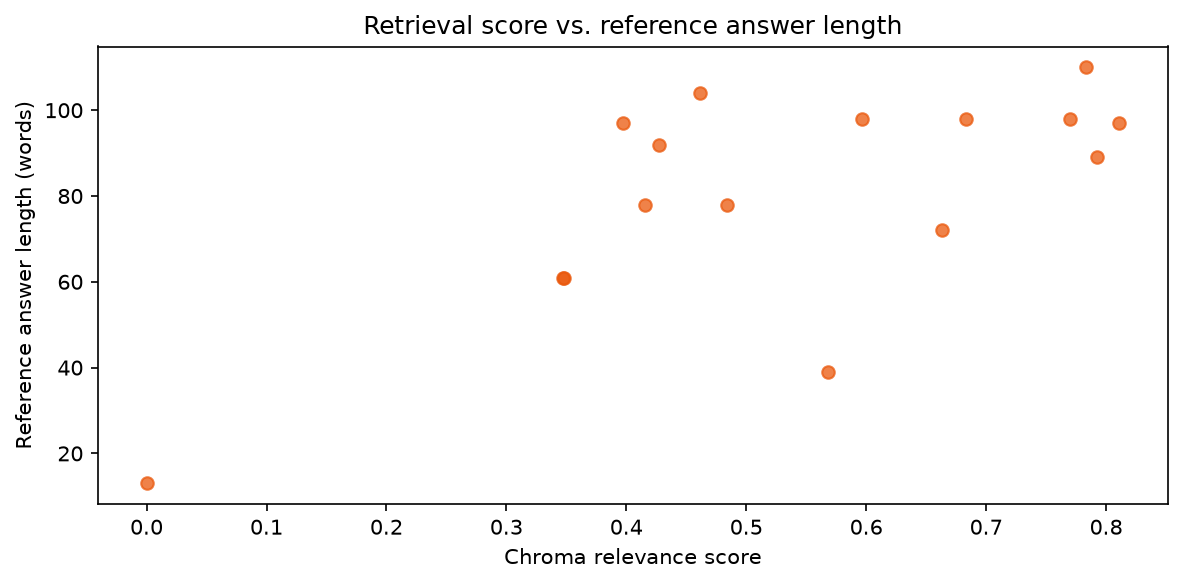

In [5]:
plt.figure(figsize=(8, 4))
plt.scatter(scores, answer_lengths, alpha=0.75, color='#ea580c')
plt.title('Retrieval score vs. reference answer length')
plt.xlabel('Chroma relevance score')
plt.ylabel('Reference answer length (words)')
plt.tight_layout()
plt.show()